In [13]:
import xarray as xr 
import pandas as pd
import matplotlib.pyplot as plt
from oceanum.datamesh import Connector

datamesh = Connector()

In [5]:
ds = xr.open_dataset("/home/nn411/Projects/OceanAtm/Moana-2.0/Data/atm_ifs_raw_2026-01-01_90D.nc")

print(ds.sizes["time"])                                                     # 724
print(ds.time.values[0], "->", ds.time.values[-1])                          # Dec 31 15Z -> Apr 1 00Z
print("gaps:", (ds.time.diff("time") != pd.Timedelta("3h")).sum().values)   # 0
print(float(ds.longitude.min()), "->", float(ds.longitude.max()))           # ~160.75 -> ~185.25
print(list(ds.data_vars))                                                   # all 8
print("NaNs:", {v: int(ds[v].isnull().sum()) for v in ds.data_vars})       # all 0

724
2025-12-31T15:00:00.000000000 -> 2026-04-01T00:00:00.000000000
gaps: 0
160.75 -> 185.25
['u10', 'v10', 't2m', 'd2m', 'msl', 'tp', 'ssr', 'strd']
NaNs: {'u10': 0, 'v10': 0, 't2m': 0, 'd2m': 0, 'msl': 0, 'tp': 0, 'ssr': 0, 'strd': 0}


In [6]:
print(ds)

<xarray.Dataset> Size: 200MB
Dimensions:    (time: 724, latitude: 87, longitude: 99)
Coordinates:
  * time       (time) datetime64[ns] 6kB 2025-12-31T15:00:00 ... 2026-04-01
  * latitude   (latitude) float32 348B -52.25 -52.0 -51.75 ... -31.0 -30.75
  * longitude  (longitude) float32 396B 160.8 161.0 161.2 ... 184.8 185.0 185.2
Data variables:
    u10        (time, latitude, longitude) float32 25MB -1.575 -2.028 ... 0.5771
    v10        (time, latitude, longitude) float32 25MB -1.627 -1.627 ... 2.808
    t2m        (time, latitude, longitude) float32 25MB 281.8 282.0 ... 295.3
    d2m        (time, latitude, longitude) float32 25MB 280.6 280.5 ... 291.6
    msl        (time, latitude, longitude) float32 25MB 1.004e+05 ... 1.015e+05
    tp         (time, latitude, longitude) float32 25MB 1.766e-10 ... 3.885e-09
    ssr        (time, latitude, longitude) float32 25MB 1.192e-05 ... 627.7
    strd       (time, latitude, longitude) float32 25MB 324.4 333.3 ... 381.2
Attributes:
    title: 

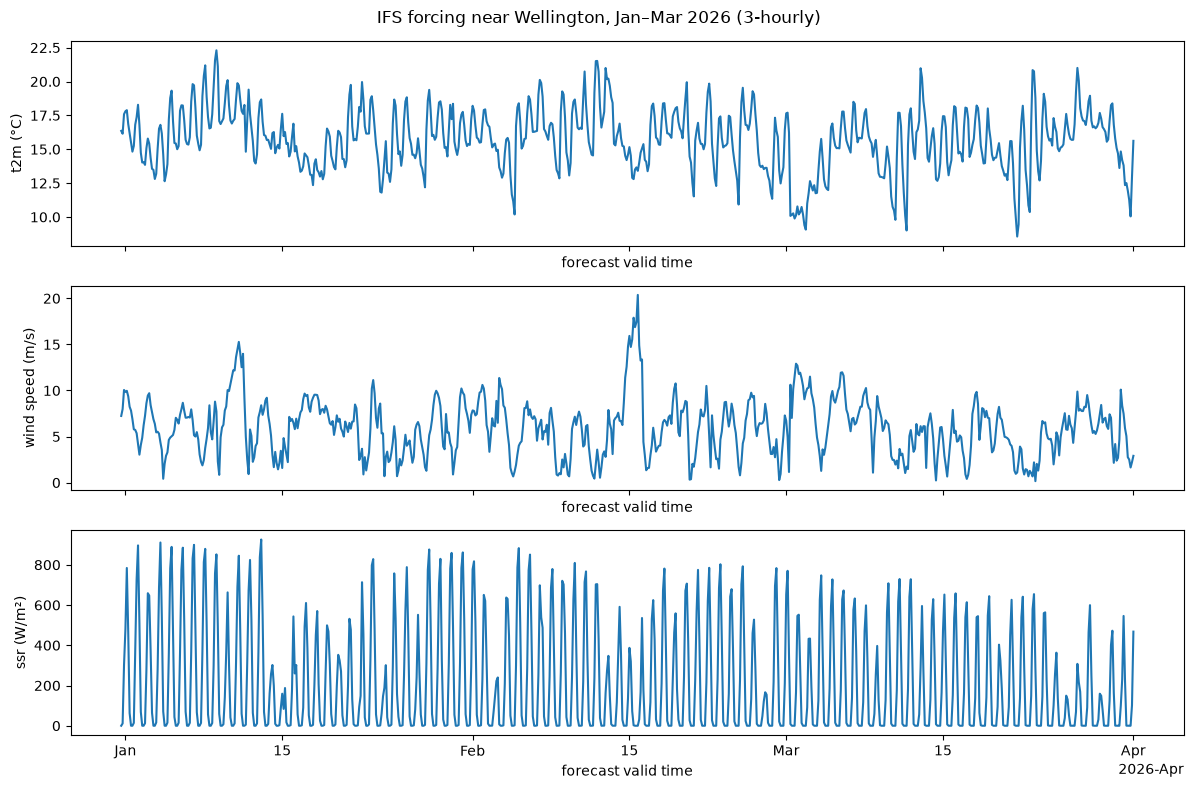

In [8]:
pt = ds.sel(longitude=174.78, latitude=-41.28, method="nearest")   # near Wellington

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
(pt.t2m - 273.15).plot(ax=axes[0]);  axes[0].set_ylabel("t2m (°C)")
((pt.u10**2 + pt.v10**2) ** 0.5).plot(ax=axes[1]);  axes[1].set_ylabel("wind speed (m/s)")
pt.ssr.plot(ax=axes[2]);  axes[2].set_ylabel("ssr (W/m²)")
for ax in axes: ax.set_title("")
fig.suptitle("IFS forcing near Wellington, Jan–Mar 2026 (3-hourly)")
plt.tight_layout()

Text(0.5, 1.0, '2 m temperature, 2026-01-13 03:00 UTC')

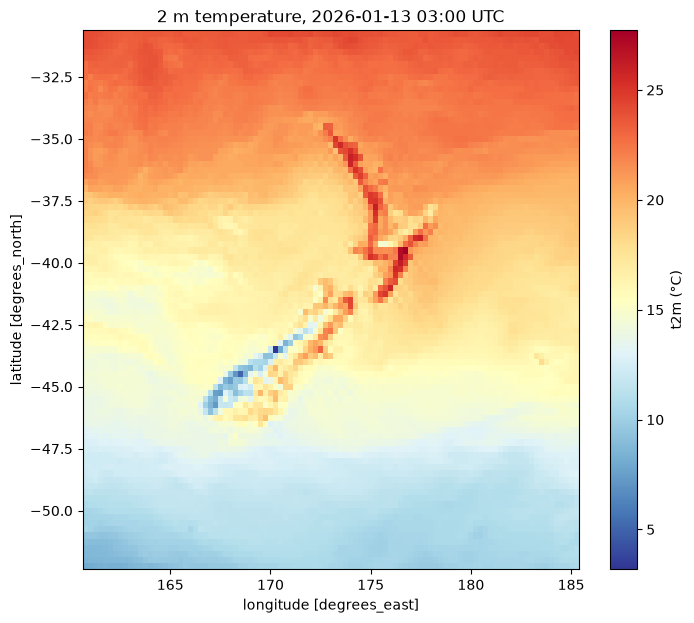

In [9]:
fig, ax = plt.subplots(figsize=(8, 7))
(ds.t2m.isel(time=100) - 273.15).plot(ax=ax, cmap="RdYlBu_r", cbar_kwargs={"label": "t2m (°C)"})
ax.set_title(f"2 m temperature, {pd.Timestamp(ds.time.values[100]):%Y-%m-%d %H:%M} UTC")

In [10]:
print(ds.time.diff("time").to_series().value_counts())

time
0 days 03:00:00    723
Name: count, dtype: int64


In [11]:
summary = pd.DataFrame({
    v: {"units": ds[v].attrs.get("units", ""),
        "min": float(ds[v].min()), "mean": float(ds[v].mean()), "max": float(ds[v].max())}
    for v in ds.data_vars
}).T
print(summary)

        units         min           mean          max
u10   m s**-1  -26.261078       1.378655      31.5009
v10   m s**-1  -26.399246       0.403424    30.751663
t2m         K   267.75531     289.539398   307.675598
d2m         K  254.312576     285.613373   297.783813
msl        Pa    96485.75  101271.054688  104189.3125
tp    m s**-1         0.0            0.0     0.000013
ssr   W m**-2         0.0     211.613632  1031.514038
strd  W m**-2  209.563354     346.039825   444.909088


Text(0.5, 1.0, '4 days near Wellington; dashed = cycle joins (00Z/12Z)')

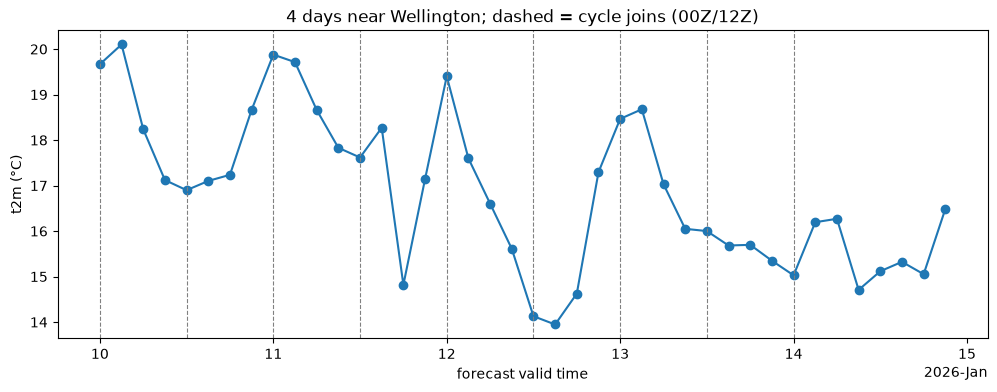

In [12]:
pt = ds.sel(longitude=174.78, latitude=-41.28, method="nearest")
week = pt.sel(time=slice("2026-01-10", "2026-01-14"))

fig, ax = plt.subplots(figsize=(12, 4))
(week.t2m - 273.15).plot(ax=ax, marker="o")
for t in pd.date_range("2026-01-10", "2026-01-14", freq="12h"):
    ax.axvline(t, color="grey", ls="--", lw=0.8)      # cycle boundaries
ax.set_ylabel("t2m (°C)"); ax.set_title("4 days near Wellington; dashed = cycle joins (00Z/12Z)")

Text(0.5, 1.0, 'Chained short forecasts vs one long forecast')

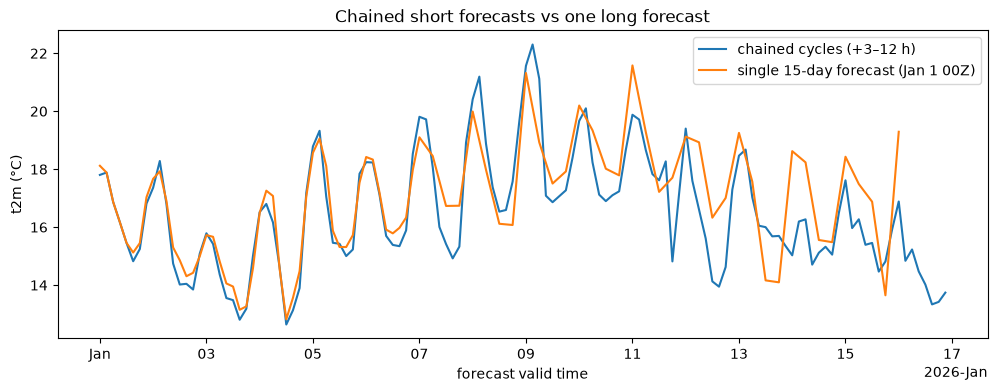

In [14]:
long = datamesh.query(
    datasource="ecmwf_ifs_0p25_oper_sfc", variables=["t2m"],
    parameters={"cycle": "2026010100"},
    timefilter={"type": "range", "times": ["2026-01-01", "2026-01-16"]},
    geofilter={"type": "bbox", "geom": [174.5, -41.5, 175.0, -41.0]},
).sel(longitude=174.78, latitude=-41.28, method="nearest")

fig, ax = plt.subplots(figsize=(12, 4))
(pt.t2m.sel(time=slice("2026-01-01", "2026-01-16")) - 273.15).plot(ax=ax, label="chained cycles (+3–12 h)")
(long.t2m - 273.15).plot(ax=ax, label="single 15-day forecast (Jan 1 00Z)")
ax.legend(); ax.set_ylabel("t2m (°C)"); ax.set_title("Chained short forecasts vs one long forecast")

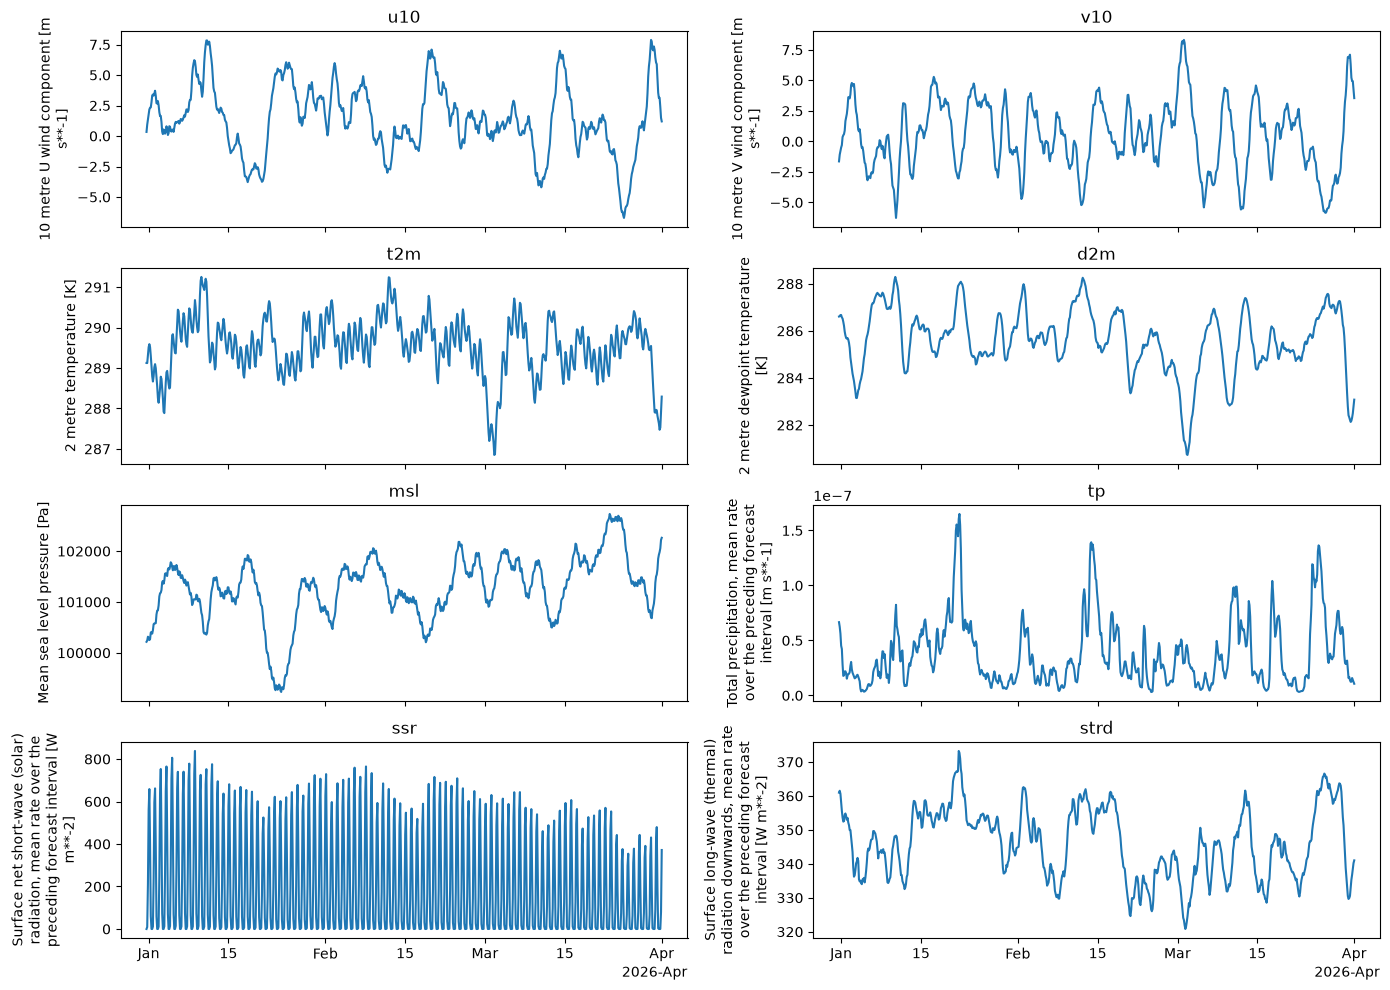

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)
for ax, v in zip(axes.flat, ds.data_vars):
    ds[v].mean(["latitude", "longitude"]).plot(ax=ax)
    ax.set_title(v); ax.set_xlabel("")
plt.tight_layout()